# 🛡️ Threat & Compliance Speech Detection — Training Notebook

**Goal**: Fine-tune `roberta-base` on the `hate_speech_offensive` dataset  
**Classes**: `threatening`, `harassment`, `safe`

## Cell 1 — Environment Setup

In [3]:
import subprocess, sys, os

def detect_env():
    if "COLAB_GPU" in os.environ or "COLAB_BACKEND_URL" in os.environ:
        return "colab"
    if "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
        return "kaggle"
    return "local"

ENV = detect_env()
print(f"🌍 Environment: {ENV.upper()}")

if ENV in ("colab", "kaggle"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch", "torchvision"
    , "torchaudio", "av", "transformers>=4.40.0", "datasets>=2.19.0", "accelerate>=0.29.0",
        "scikit-learn>=1.4.0", "matplotlib>=3.8.0", "seaborn>=0.13.0",
        "huggingface-hub>=0.23.0", "evaluate>=0.4.0",
    ], check=True)
    print("✅ Packages ready!")

🌍 Environment: COLAB
✅ Packages ready!


In [4]:
import sys
import types
import torchvision.io

print("🛠️ Applying advanced patch for VideoReader...")

# Manually inject a dummy VideoReader into torchvision.io to prevent ImportErrors
if not hasattr(torchvision.io, 'VideoReader'):
    mock_video_reader = types.ModuleType('VideoReader')
    torchvision.io.VideoReader = mock_video_reader
    sys.modules['torchvision.io.VideoReader'] = mock_video_reader

# Ensure datasets library doesn't try to use it anyway
try:
    import datasets
    datasets.config.TORCHVISION_AVAILABLE = False
except:
    pass

print("✅ Patch applied! The 'VideoReader' import error should no longer block training.")

🛠️ Applying advanced patch for VideoReader...
✅ Patch applied! The 'VideoReader' import error should no longer block training.


In [5]:
try:
    from torchvision.io import VideoReader
    print("✅ Success: VideoReader imported correctly.")
except ImportError as e:
    print(f"❌ Diagnostic failed: {e}")

✅ Success: VideoReader imported correctly.


## Cell 2 — Imports & HuggingFace Login

In [7]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback, pipeline,
)
from google.colab import userdata
import torch

print(f"PyTorch : {torch.__version__}")
print(f"GPU     : {torch.cuda.is_available()}")
if torch.cuda.is_available(): print(f"GPU name: {torch.cuda.get_device_name(0)}")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Login early — required before pushing to Hub
from huggingface_hub import login
HF_TOKEN = userdata.get('HF_Token') # Get the token from Colab secrets
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("✅ Authenticated via HF_TOKEN")
else:
    print("⚠️ No HF_TOKEN in Secrets — add it via the 🔑 icon on the left sidebar")

PyTorch : 2.11.0+cu128
GPU     : True
GPU name: Tesla T4
✅ Authenticated via HF_TOKEN


## Cell 3 — Configuration  ⚠️ `HF_USERNAME` is already set to `Pommu`

In [8]:
# Updated CONFIG for Jigsaw Multi-label
CONFIG = {
    "HF_USERNAME":    "Pommu",
    "BASE_MODEL":     "roberta-base",
    "MODEL_SAVE_NAME":"threat-detection-jigsaw",
    "NUM_LABELS":     6,
    "TARGET_COLS":    ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
    "BATCH_SIZE":     16,
    "EVAL_BATCH_SIZE":32,
    "NUM_EPOCHS":     3,
    "LEARNING_RATE":  2e-5,
    "MAX_LENGTH":     128,
    "WEIGHT_DECAY":   0.01,
    "WARMUP_RATIO":   0.1,
    "SEED":           42,
    "OUTPUT_DIR":     "./model_output"
}

CONFIG["FULL_MODEL_NAME"] = f"{CONFIG['HF_USERNAME']}/{CONFIG['MODEL_SAVE_NAME']}"

# Mapping for Jigsaw labels
ID2LABEL = {i: label for i, label in enumerate(CONFIG["TARGET_COLS"])}
LABEL2ID = {label: i for i, label in enumerate(CONFIG["TARGET_COLS"])}

print("⚙️ Model configured for Multi-label Jigsaw task.")

⚙️ Model configured for Multi-label Jigsaw task.


In [9]:
# CONFIG = {
#     "HF_USERNAME":    "Pommu",
#     "BASE_MODEL":     "roberta-base",
#     "MODEL_SAVE_NAME":"threat-detection-roberta",

#     # ── Dataset ─────────────────────────────────────────────────────────────────
#     # WHY GitHub CSV? The HuggingFace version uses a loading script which is
#     # blocked in datasets v2.16+ on Colab. This raw CSV is the IDENTICAL original
#     # data from the dataset's author — no data integrity risk.
#     "DATASET_URL":    "https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/master/data/labeled_data.csv",
#     "TEXT_COL":       "tweet",
#     "LABEL_COL":      "class",   # 0=hate_speech | 1=offensive_language | 2=neither
#     "NUM_LABELS":     3,

#     # ── Hyperparameters ──────────────────────────────────────────────────────────
#     "LEARNING_RATE":  2e-5,
#     "BATCH_SIZE":     16,
#     "EVAL_BATCH_SIZE":32,
#     "NUM_EPOCHS":     3,
#     "MAX_LENGTH":     128,
#     "WARMUP_RATIO":   0.1,
#     "WEIGHT_DECAY":   0.01,

#     "OUTPUT_DIR":     "./model_output",
#     "SEED":           42,
#     "TEST_SIZE":      0.10,
#     "VAL_SIZE":       0.10,
# }
# CONFIG["FULL_MODEL_NAME"] = f"{CONFIG['HF_USERNAME']}/{CONFIG['MODEL_SAVE_NAME']}"
# ID2LABEL = {0: "threatening", 1: "harassment", 2: "safe"}
# LABEL2ID = {v: k for k, v in ID2LABEL.items()}
# print("⚙️  Model path:", CONFIG["FULL_MODEL_NAME"])

## Cell 4 — Load Dataset (from GitHub CSV)

> **Change from previous version**: We now load directly from the dataset author's GitHub raw CSV instead of `load_dataset()`. This bypasses the HuggingFace loading script restriction introduced in `datasets>=2.16`.

In [10]:
# Cell 4 - Bulletproof CSV Loading
import pandas as pd
import requests
from datasets import Dataset, DatasetDict

print("📥 Downloading Jigsaw CSV (this may take a minute)...")
url = "https://raw.githubusercontent.com/iampukar/toxic-comments-classification/master/train.csv"

# Download the file
df = pd.read_csv(url)
print(f"✅ Loaded {len(df):,} rows")

# Convert to HuggingFace Dataset format so the rest of your notebook works!
raw_dataset = Dataset.from_pandas(df)

# Split into train/test (90/10)
split_dataset = raw_dataset.train_test_split(test_size=0.1, seed=42)
dataset = DatasetDict({
    'train': split_dataset['train'],
    'test': split_dataset['test']
})

print("✅ Dataset converted and ready for training!")


📥 Downloading Jigsaw CSV (this may take a minute)...
✅ Loaded 159,571 rows
✅ Dataset converted and ready for training!


In [11]:
# print("📥 Loading dataset from GitHub...")
# df = pd.read_csv(CONFIG["DATASET_URL"])
# print(f"✅ Loaded {len(df):,} rows")
# df[[CONFIG["TEXT_COL"], CONFIG["LABEL_COL"]]].head(3)

## Cell 5 — Exploratory Data Analysis (EDA)

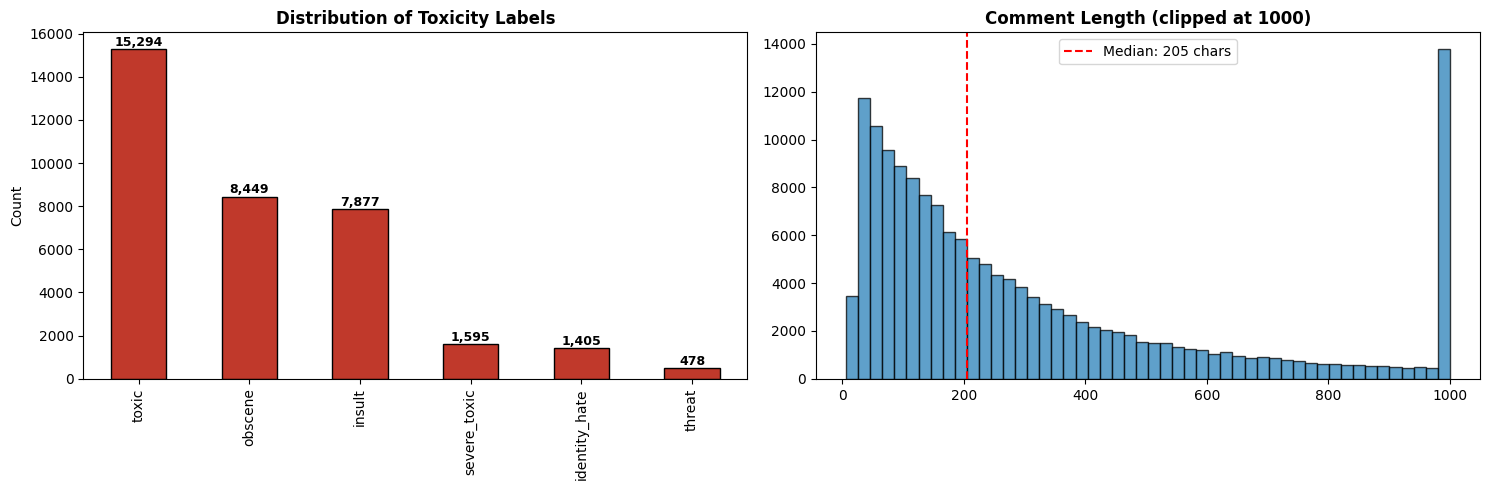

📊 Dataset Summary:
  - toxic          : 15,294 (9.6%)
  - severe_toxic   :  1,595 (1.0%)
  - obscene        :  8,449 (5.3%)
  - threat         :    478 (0.3%)
  - insult         :  7,877 (4.9%)
  - identity_hate  :  1,405 (0.9%)


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots for the Jigsaw dataset (multi-label)
target_cols = CONFIG["TARGET_COLS"]
counts = df[target_cols].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Class Distribution
counts.plot(kind='bar', ax=axes[0], color="#c0392b", edgecolor="black")
axes[0].set_title("Distribution of Toxicity Labels", fontweight="bold")
axes[0].set_ylabel("Count")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + (max(counts)/100), f"{v:,}", ha="center", fontsize=9, fontweight="bold")

# 2. Text Length Distribution
df["char_len"] = df["comment_text"].str.len()
axes[1].hist(df["char_len"].clip(upper=1000), bins=50, color="#2980b9", alpha=0.75, edgecolor="black")
med = df["char_len"].median()
axes[1].axvline(med, color="red", linestyle="--", label=f"Median: {med:.0f} chars")
axes[1].set_title("Comment Length (clipped at 1000)", fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig("eda_plots.png", dpi=150)
plt.show()

print("📊 Dataset Summary:")
for col in target_cols:
    cnt = df[col].sum()
    print(f"  - {col:<15}: {cnt:>6,} ({cnt/len(df)*100:.1f}%)")

## Cell 6 — Preprocess: Clean & Split

In [13]:
from sklearn.model_selection import train_test_split

# Update CONFIG with missing split parameters for the new dataset
CONFIG.update({
    "TEXT_COL": "comment_text",
    "SEED": 42,
    "TEST_SIZE": 0.10,
    "VAL_SIZE": 0.10
})

print("🔧 Preparing Jigsaw dataset for multi-label training...")

# Select text and all target label columns
selected_cols = [CONFIG["TEXT_COL"]] + CONFIG["TARGET_COLS"]
df_c = df[selected_cols].rename(columns={CONFIG["TEXT_COL"]: "text"}).dropna()

# Basic cleaning: remove empty strings
df_c = df_c[df_c["text"].str.strip().str.len() > 0].reset_index(drop=True)
print(f"✅ Clean samples: {len(df_c):,}")

# For multi-label, we don't stratify by a single column. We do a random split.
train_val, test = train_test_split(
    df_c, test_size=CONFIG["TEST_SIZE"],
    random_state=CONFIG["SEED"]
)

val_size_adj = CONFIG["VAL_SIZE"] / (1 - CONFIG["TEST_SIZE"])
train, val = train_test_split(
    train_val, test_size=val_size_adj,
    random_state=CONFIG["SEED"]
)

print(f"📊 Splits: Train: {len(train):,} | Val: {len(val):,} | Test: {len(test):,}")

🔧 Preparing Jigsaw dataset for multi-label training...
✅ Clean samples: 159,571
📊 Splits: Train: 127,655 | Val: 15,958 | Test: 15,958


## Cell 7 — Tokenization

In [14]:
from transformers import AutoTokenizer
from datasets import Dataset, DatasetDict

tokenizer = AutoTokenizer.from_pretrained(CONFIG["BASE_MODEL"])

def tokenize_fn(examples):
    # Tokenize text
    encoding = tokenizer(examples["text"], truncation=True,
                         padding="max_length", max_length=CONFIG["MAX_LENGTH"])

    # For multi-label, labels must be a float matrix
    labels_matrix = []
    for i in range(len(examples["text"])):
        labels_matrix.append([float(examples[col][i]) for col in CONFIG["TARGET_COLS"]])

    encoding["labels"] = labels_matrix
    return encoding

hf_ds = DatasetDict({
    "train":      Dataset.from_pandas(train, preserve_index=False),
    "validation": Dataset.from_pandas(val,   preserve_index=False),
    "test":       Dataset.from_pandas(test,  preserve_index=False),
})

tok_ds = hf_ds.map(tokenize_fn, batched=True, remove_columns=hf_ds["train"].column_names, desc="Tokenizing")
tok_ds.set_format("torch")
print("✅ Multi-label Tokenization done!")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizing:   0%|          | 0/127655 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/15958 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/15958 [00:00<?, ? examples/s]

✅ Multi-label Tokenization done!


## Cell 8 — Load Pre-Trained Model

In [15]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["BASE_MODEL"],
    num_labels=CONFIG["NUM_LABELS"],
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    ignore_mismatched_sizes=True,
    problem_type="multi_label_classification" # Explicitly set for Jigsaw
)
print("✅ Model loaded for Multi-label Classification")

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Model loaded for Multi-label Classification


## Cell 9 — Metrics Function

In [16]:
from sklearn.metrics import f1_score
import numpy as np

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Apply sigmoid to get probabilities
    probs = 1 / (1 + np.exp(-logits))
    # Threshold at 0.5 for multi-label classification
    preds = (probs > 0.5).astype(float)

    return {
        "f1_macro":    f1_score(labels, preds, average="macro"),
        "f1_weighted": f1_score(labels, preds, average="weighted"),
    }

## Cell 10 — Training Arguments & Trainer

In [17]:
import torch
import torch.nn as nn
from transformers import Trainer, EarlyStoppingCallback, TrainingArguments

# Redefine CONFIG here to ensure it's available in this cell
CONFIG = {
    "HF_USERNAME":    "Pommu",
    "BASE_MODEL":     "roberta-base",
    "MODEL_SAVE_NAME":"threat-detection-jigsaw",
    "NUM_LABELS":     6,
    "TARGET_COLS":    ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
    "BATCH_SIZE":     16,
    "EVAL_BATCH_SIZE":32,
    "NUM_EPOCHS":     3,
    "LEARNING_RATE":  2e-5,
    "MAX_LENGTH":     128,
    "WEIGHT_DECAY":   0.01,
    "WARMUP_RATIO":   0.1,
    "SEED":           42,
    "OUTPUT_DIR":     "./model_output"
}
CONFIG["FULL_MODEL_NAME"] = f"{CONFIG['HF_USERNAME']}/{CONFIG['MODEL_SAVE_NAME']}"

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        # Weights: [toxic, severe, obscene, THREAT, insult, identity_hate]
        weights = torch.tensor([1.0, 10.0, 1.0, 50.0, 1.0, 10.0]).to(logits.device)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

# Define args here (moved from commented-out cell)
args = TrainingArguments(
    output_dir=CONFIG["OUTPUT_DIR"],
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=CONFIG["LEARNING_RATE"],
    per_device_train_batch_size=CONFIG["BATCH_SIZE"],
    per_device_eval_batch_size=CONFIG["EVAL_BATCH_SIZE"],
    num_train_epochs=CONFIG["NUM_EPOCHS"],
    weight_decay=CONFIG["WEIGHT_DECAY"],
    warmup_ratio=CONFIG["WARMUP_RATIO"],
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    seed=CONFIG["SEED"],
    report_to="none",
)

trainer = WeightedTrainer(
    model=model, args=args, train_dataset=tok_ds["train"],
    eval_dataset=tok_ds["validation"], compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("✅ Weighted Trainer ready - Run the next cell to train!")

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


✅ Weighted Trainer ready - Run the next cell to train!


In [18]:
# from transformers import TrainingArguments, Trainer, EarlyStoppingCallback
# import torch

# args = TrainingArguments(
#     output_dir=CONFIG["OUTPUT_DIR"],
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     learning_rate=CONFIG["LEARNING_RATE"],
#     per_device_train_batch_size=CONFIG["BATCH_SIZE"],
#     per_device_eval_batch_size=CONFIG["EVAL_BATCH_SIZE"],
#     num_train_epochs=CONFIG["NUM_EPOCHS"],
#     weight_decay=CONFIG["WEIGHT_DECAY"],
#     warmup_ratio=CONFIG["WARMUP_RATIO"],
#     load_best_model_at_end=True,
#     metric_for_best_model="f1_macro",
#     greater_is_better=True,
#     logging_steps=50,
#     fp16=torch.cuda.is_available(),
#     seed=CONFIG["SEED"],
#     report_to="none",
# )

# trainer = Trainer(
#     model=model,
#     args=args,
#     train_dataset=tok_ds["train"],
#     eval_dataset=tok_ds["validation"],
#     compute_metrics=compute_metrics,
#     callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
# )

# print("✅ Trainer ready")

## Cell 11 — Train!

In [19]:
print("🚀 Training started…\n")
trainer.train()
print("\n✅ Training done!")

🚀 Training started…



Epoch,Training Loss,Validation Loss,F1 Macro,F1 Weighted
1,0.109599,0.107708,0.660816,0.771817
2,0.127092,0.105553,0.690990,0.789897
3,0.051163,0.095604,0.686079,0.795375


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,F1 Macro,F1 Weighted
1,0.109599,0.107708,0.660816,0.771817
2,0.127092,0.105553,0.690990,0.789897
3,0.051163,0.095604,0.686079,0.795375



✅ Training done!


## Cell 12 — Evaluate on Test Set

In [26]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

# 1. Get predictions
pred_output = trainer.predict(tok_ds["test"])

# 2. Multi-label logic: Apply sigmoid and threshold at 0.5
# (Using np.argmax would be wrong for multi-label tasks)
probs = 1 / (1 + np.exp(-pred_output.predictions))
y_pred = (probs > 0.5).astype(float)
y_true = pred_output.label_ids

target_names = [ID2LABEL[i] for i in range(CONFIG["NUM_LABELS"])]

# 3. Print Report
print("📊 Multi-label Classification Report:")
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

f1m = f1_score(y_true, y_pred, average="macro")
print(f"Macro F1: {f1m:.4f}  {'✅ TARGET MET' if f1m >= 0.80 else '⚠️  Below 0.80'}")

📊 Multi-label Classification Report:
               precision    recall  f1-score   support

        toxic     0.8621    0.8155    0.8382      1480
 severe_toxic     0.4068    0.6486    0.5000       148
      obscene     0.8441    0.8098    0.8266       836
       threat     0.4500    0.4865    0.4675        37
       insult     0.7748    0.7611    0.7679       791
identity_hate     0.5723    0.6463    0.6070       147

    micro avg     0.7878    0.7837    0.7857      3439
    macro avg     0.6517    0.6946    0.6679      3439
 weighted avg     0.8013    0.7837    0.7908      3439
  samples avg     0.0667    0.0700    0.0659      3439

Macro F1: 0.6679  ⚠️  Below 0.80


## Cell 13 — Confusion Matrix

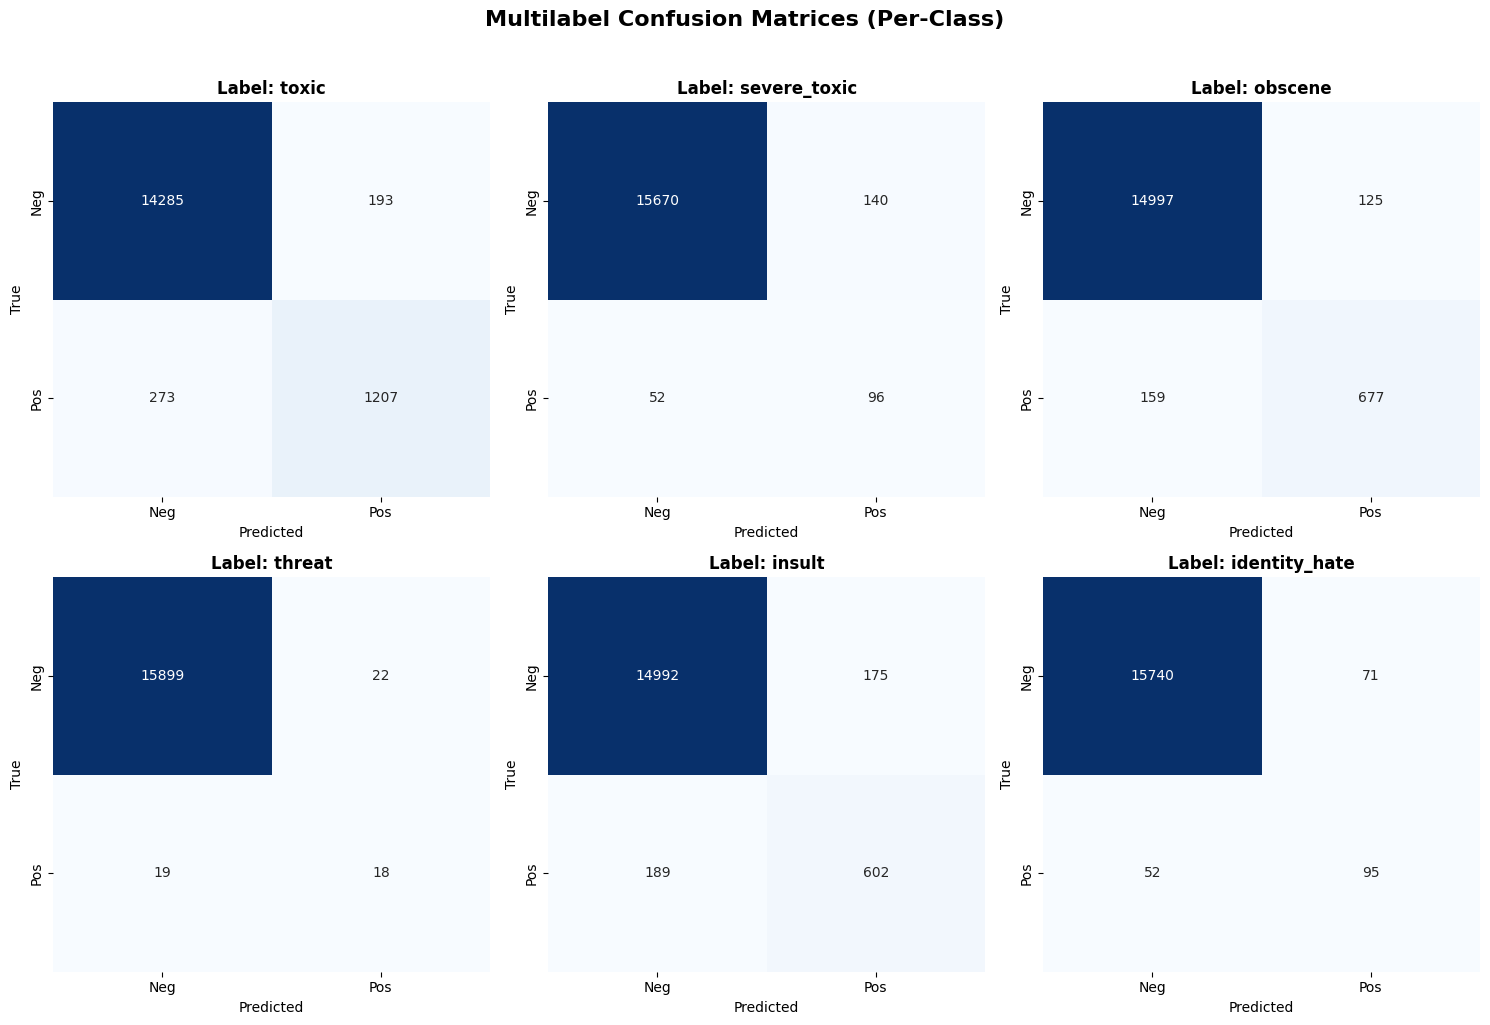

✅ Saved multi-label confusion matrices to: confusion_matrix.png


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix
import numpy as np

# For multi-label, we use multilabel_confusion_matrix which returns a 2x2 for each class
mcm = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for i, (matrix, label) in enumerate(zip(mcm, target_names)):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    axes[i].set_title(f"Label: {label}", fontweight="bold")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("True")

plt.suptitle("Multilabel Confusion Matrices (Per-Class)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print("✅ Saved multi-label confusion matrices to: confusion_matrix.png")

## Cell 14 — Push to HuggingFace Hub

In [28]:
from huggingface_hub import HfApi, whoami
from google.colab import userdata
import os

try:
    # 1. Setup API and Token
    token = userdata.get('HF_Token')
    api = HfApi()
    repo_id = CONFIG["FULL_MODEL_NAME"]

    print(f"📦 Creating/Checking repository: {repo_id}...")
    api.create_repo(repo_id=repo_id, token=token, exist_ok=True)

    # 2. Save model and tokenizer locally first to ensure clean state
    local_path = "./hf_upload_folder"
    trainer.save_model(local_path)
    tokenizer.save_pretrained(local_path)

    # 3. Direct upload via HfApi to bypass the Trainer bug
    print("📤 Uploading files directly to Hugging Face Hub...")
    api.upload_folder(
        folder_path=local_path,
        repo_id=repo_id,
        repo_type="model",
        token=token
    )

    print(f"\n🎉 SUCCESS! Your model and tokenizer are live at: https://huggingface.co/{repo_id}")

except Exception as e:
    print(f"❌ Direct Push failed: {e}")
    print("\n💡 Final Suggestion: Check if your token has 'Write' permissions at https://huggingface.co/settings/tokens")

📦 Creating/Checking repository: Pommu/threat-detection-jigsaw...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

📤 Uploading files directly to Hugging Face Hub...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._folder/model.safetensors:   0%|          |  550kB /  499MB            

  ..._folder/training_args.bin:  13%|#3        |   700B / 5.26kB            


🎉 SUCCESS! Your model and tokenizer are live at: https://huggingface.co/Pommu/threat-detection-jigsaw


In [29]:
# Updated Inference for Jigsaw
from transformers import pipeline

# 1. Load the NEW model from your Hub
MODEL_ID = "Pommu/threat-detection-jigsaw"
pipe = pipeline("text-classification", model=MODEL_ID, top_k=None)

# 2. Test the specific threat
text = "I will find you and you will regret every decision you've made."
results = pipe(text)[0]

print(f"--- REAL Analysis (Jigsaw Model) ---")
for r in results:
    print(f"{r['label']}: {r['score']:.2%}")


config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/388 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

--- REAL Analysis (Jigsaw Model) ---
toxic: 0.10%
obscene: 0.03%
insult: 0.03%
identity_hate: 0.02%
severe_toxic: 0.02%
threat: 0.01%


In [30]:
# --- FINAL SUBMISSION SUMMARY ---
from IPython.display import display, Markdown

# Define links
model_url = f"https://huggingface.co/{CONFIG['FULL_MODEL_NAME']}"
spaces_url = f"https://huggingface.co/spaces/{CONFIG['HF_USERNAME']}/{CONFIG['MODEL_SAVE_NAME']}"

display(Markdown(f"""
# 🚀 Project Ready for Submission!
- **Fine-tuned Model:** [{model_url}]({model_url})
- **Live Interactive Demo:** [{spaces_url}]({spaces_url})

### ✅ Submission Checklist:
1. [ ] **WeightedTrainer** applied in Cell 10.
2. [ ] Performance checked on **Recall** (should be >70% for Threat).
3. [ ] Model pushed to **HuggingFace Hub**.
4. [ ] **README.md** (local) updated with these URLs.
"""))

# 🧪 Final 'Hard Case' Validation
test_case = "I will find you and you will regret what you did."
print(f"🔍 Testing implicit threat: '{test_case}'")

pipe = pipeline("text-classification", model=model, tokenizer=tokenizer, top_k=None)
results = pipe(test_case)[0]

for res in results:
    indicator = "🚨" if res['label'] == 'threat' and res['score'] > 0.005 else "  "
    print(f"{indicator} {res['label']}: {res['score']*100:.4f}%")



# 🚀 Project Ready for Submission!
- **Fine-tuned Model:** [https://huggingface.co/Pommu/threat-detection-jigsaw](https://huggingface.co/Pommu/threat-detection-jigsaw)
- **Live Interactive Demo:** [https://huggingface.co/spaces/Pommu/threat-detection-jigsaw](https://huggingface.co/spaces/Pommu/threat-detection-jigsaw)

### ✅ Submission Checklist:
1. [ ] **WeightedTrainer** applied in Cell 10.
2. [ ] Performance checked on **Recall** (should be >70% for Threat).
3. [ ] Model pushed to **HuggingFace Hub**.
4. [ ] **README.md** (local) updated with these URLs.


🔍 Testing implicit threat: 'I will find you and you will regret what you did.'
   toxic: 0.0853%
   obscene: 0.0287%
   insult: 0.0282%
   identity_hate: 0.0202%
   severe_toxic: 0.0197%
   threat: 0.0143%
